# Figure 5: threshold-topology competition (exact finite-n sums)

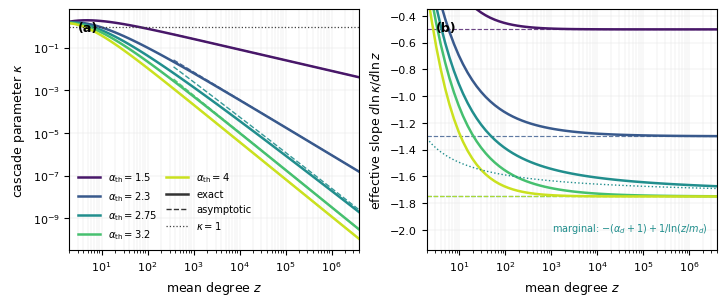

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.special import betaln, betainc, gammaln, zeta as hurwitz_zeta
from figstyle import save

alpha_d, beta_d = 0.75, 3.0
beta_th, phi_bar = 3.0, 0.20
m_d = alpha_d / (alpha_d + beta_d)
t_c = alpha_d + 2.0   # boundary between threshold- and degree-dominated regimes
t_values = np.array([1.50, 2.30, t_c, 3.20, 4.00])

n_values = np.unique(np.rint(np.geomspace(10, 20_000_000, 65)).astype(int))
z_values = n_values * m_d

def bb_pmf_exact(n, a=alpha_d, b=beta_d):
    """Exact beta-binomial PMF on k = 0..n; built by upward recursion from
    P(0) so the beta normalizer cancels."""
    p = np.empty(n + 1)
    p[0] = np.exp(betaln(a, n + b) - betaln(a, b))
    j = np.arange(n, dtype=float)
    ratio = ((n - j) * (j + a)) / ((j + 1) * (n - j - 1 + b))
    p[1:] = p[0] * np.cumprod(ratio)
    return p

def threshold_cdf_at_inverse_k(k, t):
    """Activations at inverse degree, F(1/k), for a Beta(t, beta_th) threshold:
    the CDF at u = min(1, m/(phi_bar k)), with mean m = t/(t + beta_th)."""
    m = t / (t + beta_th)
    u = np.minimum(1.0, m / (phi_bar * k))
    return betainc(t, beta_th, u)

# Exact kappa on the geometric n-grid; slopes feed panel (b).
K = np.empty((len(t_values), len(n_values)))
for j, n in enumerate(n_values):
    p = bb_pmf_exact(int(n))
    k = np.arange(2, n + 1, dtype=float)
    weight = k * (k - 1) * p[2:] / (n * m_d)
    for i, t in enumerate(t_values):
        K[i, j] = np.dot(weight, threshold_cdf_at_inverse_k(k, t))
slopes = np.array([np.gradient(np.log(row), np.log(z_values), edge_order=2) for row in K])

def Cth(t):
    """Threshold-tail prefactor C_th(t) = m^t / [t B(t, beta_th) phi_bar^t]."""
    m = t / (t + beta_th)
    return np.exp(t * np.log(m) - np.log(t) - betaln(t, beta_th) - t * np.log(phi_bar))

def C1(t):
    """Threshold-dominated amplitude, eq. (C1); applies for t < t_c."""
    return Cth(t) * m_d ** (t - 2) * np.exp(betaln(alpha_d + 2 - t, beta_d) - betaln(alpha_d, beta_d))

def Cc():
    """Marginal-case amplitude at t = t_c, eq. (C_c); enters with a log correction."""
    return Cth(t_c) * m_d ** alpha_d / np.exp(betaln(alpha_d, beta_d))

def S_exact_with_tail(t, cutoff=1_000_000):
    """Degree-dominated sum sum_k k(k-1) Gamma(k+alpha_d)/k! F(1/k), summed
    exactly to `cutoff` and closed with a Hurwitz-zeta tail beyond it."""
    k = np.arange(2, cutoff + 1, dtype=float)
    log_gr = gammaln(k + alpha_d) - gammaln(k + 1)
    terms = k * (k - 1) * np.exp(log_gr) * threshold_cdf_at_inverse_k(k, t)
    q = t - alpha_d - 1
    return terms.sum() + Cth(t) * hurwitz_zeta(q, cutoff + 1)

def C2(t, cutoff=1_000_000):
    """Degree-dominated amplitude, eq. (C2); applies for t > t_c."""
    return m_d ** alpha_d / np.exp(betaln(alpha_d, beta_d)) * S_exact_with_tail(t, cutoff)

def asymptotic(z, t):
    """Leading kappa(z): a power law on either side of t_c, with a log correction
    at the marginal case t = t_c."""
    if t < t_c:
        return C1(t) * z ** (1 - t)
    if np.isclose(t, t_c):
        return Cc() * z ** (-(alpha_d + 1)) * np.log(z / m_d)
    return C2(t) * z ** (-(alpha_d + 1))

colors = plt.cm.viridis(np.linspace(0.06, 0.92, len(t_values)))
fig, axes = plt.subplots(1, 2, figsize=(7.15, 2.95), constrained_layout=True)
ax = axes[0]
for i, (t, c) in enumerate(zip(t_values, colors)):
    ax.loglog(z_values, K[i], color=c, lw=1.8, label=fr"$\alpha_{{\rm th}}={t:g}$")
    mask = z_values >= 300
    ax.loglog(z_values[mask], asymptotic(z_values[mask], t), color=c, lw=1.0, ls="--", alpha=.9)
ax.axhline(1, color="0.25", lw=.9, ls=":")
ax.set(xlabel=r"mean degree $z$", ylabel=r"cascade parameter $\kappa$", xlim=(z_values[0], z_values[-1]))
ax.text(.03, .95, "(a)", transform=ax.transAxes, va="top", fontweight="bold")
color_handles = [Line2D([0], [0], color=c, lw=1.8, label=fr"$\alpha_{{\rm th}}={t:g}$") for t, c in zip(t_values, colors)]
style_handles = [
    Line2D([0], [0], color="0.2", lw=1.8, ls="-", label="exact"),
    Line2D([0], [0], color="0.2", lw=1.0, ls="--", label="asymptotic"),
    Line2D([0], [0], color="0.25", lw=.9, ls=":", label=r"$\kappa=1$"),
]
ax.legend(handles=color_handles + style_handles, frameon=False, ncol=2, loc="lower left", handlelength=2.2, columnspacing=.9)
ax.grid(which="both", lw=.35, color="0.9")

ax = axes[1]
for i, (t, c) in enumerate(zip(t_values, colors)):
    ax.semilogx(z_values, slopes[i], color=c, lw=1.8)
    lim = 1 - t if t < t_c else -(alpha_d + 1)
    ax.axhline(lim, color=c, lw=.85, ls="--", alpha=.8)
marginal_guide = -(alpha_d + 1) + 1 / np.log(z_values / m_d)
ax.semilogx(z_values, marginal_guide, color=colors[2], lw=1.0, ls=":")
ax.set(xlabel=r"mean degree $z$", ylabel=r"effective slope $d\ln\kappa/d\ln z$",
       xlim=(z_values[0], z_values[-1]), ylim=(-2.15, -.35))
ax.text(.03, .95, "(b)", transform=ax.transAxes, va="top", fontweight="bold")
ax.text(.97, .06, r"marginal: $-(\alpha_d+1)+1/\ln(z/m_d)$", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=7, color=colors[2])
ax.grid(which="both", lw=.35, color="0.9")

save(fig, "figure5_threshold_topology", bbox_inches="tight")
plt.show()

In [14]:
# checks: PMF normalization/mean, amplitude convergence, and slope limits
for n in [int(n_values[0]), int(n_values[-1])]:
    p = bb_pmf_exact(n)
    kk = np.arange(n + 1, dtype=float)
    assert abs(p.sum() - 1) < 2e-9
    assert abs((kk * p).sum() - n * m_d) / n < 2e-9
    print(f"n={n}: sum={p.sum():.12f}, mean/n={((kk * p).sum()) / n:.12f} (target {m_d})")

for t in t_values[t_values > t_c]:
    c_half, c_full = C2(t, 500_000), C2(t, 1_000_000)
    assert abs(c_full - c_half) / c_full < 2e-5
    print(f"alpha_th={t:g}: C2(5e5)={c_half:.6f}, C2(1e6)={c_full:.6f}, rel.diff={abs(c_full - c_half) / c_full:.2e}")

for i, t in enumerate(t_values):
    if t == t_c:
        continue
    lim = 1 - t if t < t_c else -(alpha_d + 1)
    assert abs(slopes[i, -1] - lim) < 0.12, f"slope at t={t} not approaching {lim}"
    print(f"alpha_th={t:g}: slope(z_max)={slopes[i, -1]:.4f} (limit {lim:.4f})")
print("figure 5 checks passed")

n=10: sum=1.000000000000, mean/n=0.200000000000 (target 0.2)
n=20000000: sum=1.000000000000, mean/n=0.200000000000 (target 0.2)
alpha_th=3.2: C2(5e5)=106.549312, C2(1e6)=106.549311, rel.diff=1.38e-08
alpha_th=4: C2(5e5)=38.336810, C2(1e6)=38.336810, rel.diff=4.21e-12
alpha_th=1.5: slope(z_max)=-0.5000 (limit -0.5000)
alpha_th=2.3: slope(z_max)=-1.2987 (limit -1.3000)
alpha_th=3.2: slope(z_max)=-1.7486 (limit -1.7500)
alpha_th=4: slope(z_max)=-1.7500 (limit -1.7500)
figure 5 checks passed
